# 05 — Outros Classificadores: KNN, Naive Bayes, SVM e Gradient Boosting

Até aqui, usamos só a **regressão logística**, que chegou a uma **AUC de 0,906** no notebook 04. Ela é um modelo **linear**: soma o efeito de cada coluna, e cada coluna empurra a pontuação numa única direção. Mas vimos padrões que uma soma assim não consegue seguir:
- A **idade** tem uma relação em "U" invertido com a renda (notebook 01).
- O **ganho de capital** tem um "degrau": 0% de renda alta entre 1 e 3 mil, ~98% acima de 7 mil (notebook 03).

Existem muitas outras **famílias** de classificadores, cada uma com uma ideia diferente de como separar as classes. Neste notebook vamos conhecer os clássicos:
- A **fronteira de decisão**: a forma de "enxergar" o que cada classificador faz
- **KNN** (*k-nearest neighbors*): classificar pelos vizinhos mais parecidos
- **Naive Bayes**: classificar contando frequências, com o teorema de Bayes
- **SVM** (*support vector machine*): separar as classes com a maior margem possível
- **Gradient boosting**: o modelo de árvores do ML-01, agora classificando

> ⏱️ **Este notebook demora cerca de 2 a 3 minutos para rodar**, principalmente por causa do KNN, que é lento para prever. As células mais lentas estão indicadas.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import time   # para medir quanto tempo cada modelo leva

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay

# Ferramentas novas deste notebook:
from sklearn.datasets import make_moons                  # gera um dataset "de brinquedo" com 2 colunas
from sklearn.neighbors import KNeighborsClassifier       # KNN
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import KBinsDiscretizer       # transforma números em faixas
from sklearn.svm import SVC                              # SVM

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
colunas_categoricas = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
colunas = colunas_numericas + colunas_categoricas

Como no notebook 04, vamos comparar os modelos pela **AUC**, que mede se o modelo **ordena** bem as pessoas, sem depender do limiar. Também guardamos a acurácia, a AUC no treino (para ver o overfitting) e o tempo.

In [2]:
resultados = {}      # resumo de cada modelo
auc_por_dobra = {}   # as 5 AUCs de cada modelo, para a comparação pareada no fim


def avaliar(nome, modelo, X_dados=None, y_dados=None, com_treino=True):
    """Validação cruzada com AUC e acurácia. Por padrão usa o treino inteiro, com as 12 colunas.

    com_treino=False pula a AUC no treino (útil para o KNN, em que ela é muito lenta de calcular).
    """
    if X_dados is None:   # "is None" verifica se o argumento não foi passado
        X_dados, y_dados = X_train[colunas], y_train
    inicio = time.time()
    cv_resultado = cross_validate(
        modelo, X_dados, y_dados, cv=cv,
        scoring=["roc_auc", "accuracy"],
        return_train_score=com_treino,
        n_jobs=-1,   # treina as 5 dobras ao mesmo tempo, usando vários núcleos do processador
    )
    auc_por_dobra[nome] = cv_resultado["test_roc_auc"]
    resultados[nome] = {
        "AUC validação": cv_resultado["test_roc_auc"].mean(),
        "± desvio": cv_resultado["test_roc_auc"].std(),
        # Expressão condicional "A if condição else B": usa A quando a condição é verdadeira, senão B.
        "AUC treino": cv_resultado["train_roc_auc"].mean() if com_treino else np.nan,
        "acurácia": cv_resultado["test_accuracy"].mean(),
        "tempo (s)": time.time() - inicio,
    }
    return pd.DataFrame(resultados).T


# A referência: a logística do notebook 03.
preparar_one_hot = ColumnTransformer([
    ("numericas", StandardScaler(), colunas_numericas),
    ("categoricas", Pipeline([
        ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
    ]), colunas_categoricas),
])
logistica = Pipeline([("preparar", preparar_one_hot), ("modelo", LogisticRegression(max_iter=1000))])
avaliar("Logística (nb 03)", logistica)

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1219


## 🎓 Conceito: fronteira de decisão

Todo classificador, no fundo, **divide o espaço** dos dados em regiões: numa região ele responde "classe 0", na outra, "classe 1". A linha que separa as regiões é a **fronteira de decisão**.

Com 12 colunas, o "espaço" tem 12 dimensões e não dá para desenhá-lo. Mas com **2 colunas** podemos pintar cada ponto do plano com a classe que o modelo prevê e **ver** a forma da fronteira. É a melhor maneira de entender a personalidade de cada classificador.

Analogia: imagine o mapa de um país dividido entre dois partidos. Cada método de classificação é um jeito diferente de desenhar a divisa: com uma régua (reta), em "escadinha" seguindo os quarteirões, ou com um contorno que segue as cidades uma a uma.

Para isso, vamos usar o `make_moons`, um dataset "de brinquedo" com 2 colunas e duas classes em formato de **meia-lua**, encaixadas uma na outra. Nenhuma reta consegue separá-las.

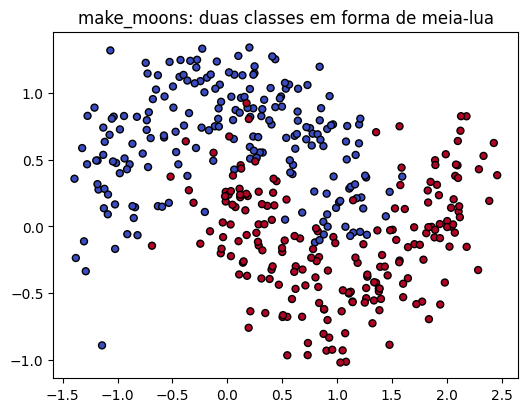

In [3]:
# 400 pontos com um pouco de ruído (noise), para as classes se misturarem nas bordas.
X_luas, y_luas = make_moons(n_samples=400, noise=0.25, random_state=42)

fig, ax = plt.subplots(figsize=(6, 4.5))
# X_luas[:, 0] é a primeira coluna (eixo x); X_luas[:, 1], a segunda (eixo y). c= colore cada ponto pela classe.
ax.scatter(X_luas[:, 0], X_luas[:, 1], c=y_luas, cmap="coolwarm", edgecolor="k", s=25)
ax.set_title("make_moons: duas classes em forma de meia-lua")
plt.show()

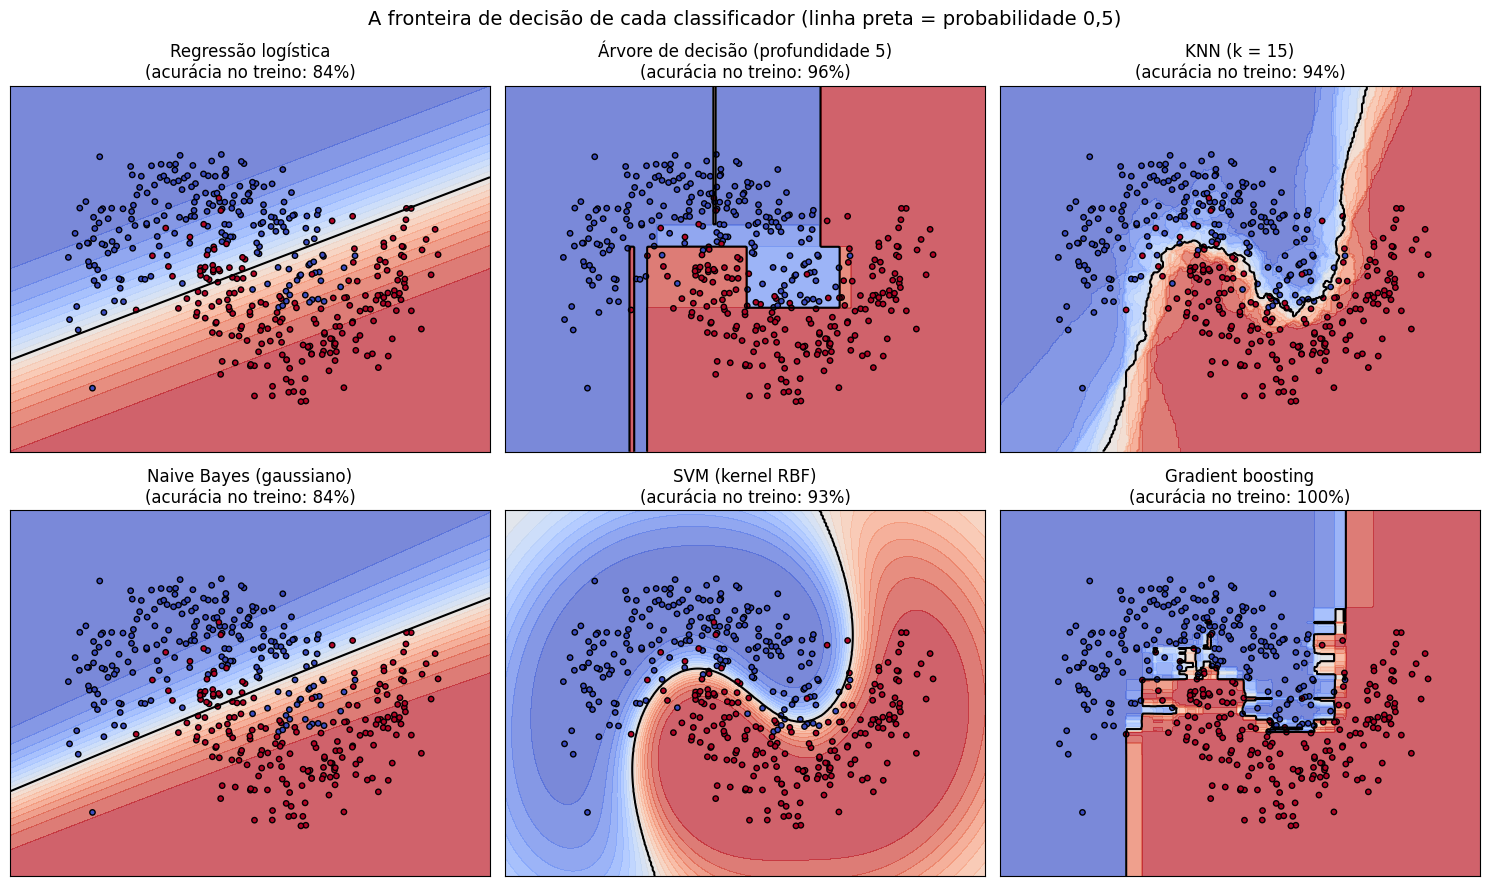

In [4]:
def desenhar_fronteira(modelo, ax, titulo):
    """Treina o modelo nas meias-luas e pinta o plano com a probabilidade prevista da classe 1."""
    modelo.fit(X_luas, y_luas)
    # np.meshgrid cria uma "grade" de pontos cobrindo todo o gráfico: 300 × 300 pontos.
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    grade = np.column_stack([xx.ravel(), yy.ravel()])   # junta as coordenadas numa tabela de 2 colunas
    prob = modelo.predict_proba(grade)[:, 1].reshape(xx.shape)   # .reshape volta ao formato da grade
    ax.contourf(xx, yy, prob, levels=20, cmap="coolwarm", alpha=0.7)   # pinta as regiões
    ax.contour(xx, yy, prob, levels=[0.5], colors="k", linewidths=1.5)  # a fronteira: probabilidade 0,5
    ax.scatter(X_luas[:, 0], X_luas[:, 1], c=y_luas, cmap="coolwarm", edgecolor="k", s=15)
    acuracia = modelo.score(X_luas, y_luas)   # .score: acurácia nos próprios dados de treino
    ax.set_title(f"{titulo}\n(acurácia no treino: {acuracia:.0%})")
    ax.set_xticks([])
    ax.set_yticks([])


modelos_fronteira = [
    (LogisticRegression(), "Regressão logística"),
    (DecisionTreeClassifier(max_depth=5, random_state=42), "Árvore de decisão (profundidade 5)"),
    (KNeighborsClassifier(n_neighbors=15), "KNN (k = 15)"),
    (GaussianNB(), "Naive Bayes (gaussiano)"),
    (SVC(probability=True, random_state=42), "SVM (kernel RBF)"),
    (HistGradientBoostingClassifier(random_state=42), "Gradient boosting"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
# axes.ravel() transforma a grade 2×3 de gráficos numa lista simples de 6, para usar no zip.
for (modelo, titulo), ax in zip(modelos_fronteira, axes.ravel()):
    desenhar_fronteira(modelo, ax, titulo)
plt.suptitle("A fronteira de decisão de cada classificador (linha preta = probabilidade 0,5)", fontsize=14)
plt.tight_layout()
plt.show()

**Conclusão:** cada classificador tem uma "personalidade" bem visível:
- **Regressão logística:** a fronteira é uma **reta**. Ela não consegue seguir as meias-luas e erra todos os pontos do "encaixe" (84% de acurácia).
- **Árvore de decisão:** a fronteira é feita de **retângulos**, porque cada pergunta corta o plano na horizontal ou na vertical. Ela segue melhor as luas (96%), mas cria regiões estranhas, como a faixa vermelha fininha à esquerda, criada para acertar um ou dois pontos: um sinal de **overfitting**.
- **KNN:** uma fronteira **curva e irregular**, que segue os pontos de perto (94%).
- **Naive Bayes (gaussiano):** aqui a fronteira saiu quase **reta**, parecida com a da logística (84%). Supondo cada coluna independente e com distribuição em forma de sino, ele não consegue representar o formato curvo das luas.
- **SVM (RBF):** uma curva **suave**, que acompanha o encaixe das luas sem se contorcer (93%).
- **Gradient boosting:** blocos retangulares, como a árvore, mas muito mais detalhados: acerta **100%** do treino, contornando cada ponto vermelho perdido do lado azul. Num dataset pequeno e com ruído como este, isso é decorar.

⚠️ A acurácia aqui é **no treino**, então ela mostra quanto cada modelo **consegue se ajustar**, e não quanto ele vai acertar em pontos novos. Uma fronteira que se ajusta demais (árvore, boosting) não é necessariamente melhor do que uma suave (SVM). No Adult, vamos comparar todos com validação cruzada.

## 🎓 Conceito: KNN (k vizinhos mais próximos)

O **KNN** é o classificador mais intuitivo de todos. Para classificar uma pessoa nova:
1. Ele procura, no treino, as **k pessoas mais parecidas** com ela (os "vizinhos mais próximos").
2. A probabilidade prevista é a **proporção de vizinhos** de cada classe. Se 12 dos 15 vizinhos ganham mais de 50 mil, a probabilidade é 12/15 = **0,8**.

"Parecido" é medido pela **distância** entre as pessoas, usando as colunas como coordenadas, como a distância entre dois pontos num mapa:
$$\text{distância} = \sqrt{(\text{idade}_A - \text{idade}_B)^2 + (\text{horas}_A - \text{horas}_B)^2 + \dots}$$

Analogia: para saber se um filme vai te agradar, você pergunta aos amigos com o **gosto mais parecido** com o seu e vai com a maioria.

Duas características importantes:
- **O KNN não "aprende" nada no `fit`**: ele só guarda o treino inteiro. Todo o trabalho acontece na **previsão**, quando ele precisa calcular a distância até **todas** as pessoas do treino. Por isso ele é chamado de **aprendiz preguiçoso** (*lazy learner*): treina num instante e prevê devagar.
- **O hiperparâmetro principal é o k.** Com k pequeno, o modelo segue cada detalhe (overfitting); com k grande, ele "alisa" demais (underfitting).

## 2. KNN: a escala das colunas é o peso delas

No ML-01, o `StandardScaler` ajudava alguns modelos e era indiferente para as árvores. No KNN, ele muda o **próprio significado** de "parecido", porque a distância soma as diferenças de todas as colunas. Veja três pessoas:

In [5]:
# pd.Series a partir de um dicionário: cada chave vira o nome de uma posição.
pessoa_a = pd.Series({"age": 30, "education-num": 10, "capital-gain": 0, "capital-loss": 0, "hours-per-week": 40})
pessoa_b = pd.Series({"age": 60, "education-num": 16, "capital-gain": 0, "capital-loss": 0, "hours-per-week": 40})
pessoa_c = pd.Series({"age": 30, "education-num": 10, "capital-gain": 1000, "capital-loss": 0, "hours-per-week": 40})


def distancia(p, q):
    """Distância entre duas pessoas: raiz da soma das diferenças ao quadrado."""
    return np.sqrt(((p - q) ** 2).sum())


print(f"A × B (30 anos a mais e de 'algum ensino superior' a doutorado): {distancia(pessoa_a, pessoa_b):,.0f}")
print(f"A × C (iguais, exceto por US$ 1.000 de ganho de capital):       {distancia(pessoa_a, pessoa_c):,.0f}")

# Com padronização: cada diferença é medida em "desvios padrão" da coluna no treino.
desvios = X_train[colunas_numericas].std()
print(f"\nPadronizado — A × B: {distancia(pessoa_a / desvios, pessoa_b / desvios):.2f}")
print(f"Padronizado — A × C: {distancia(pessoa_a / desvios, pessoa_c / desvios):.2f}")

A × B (30 anos a mais e de 'algum ensino superior' a doutorado): 31
A × C (iguais, exceto por US$ 1.000 de ganho de capital):       1,000

Padronizado — A × B: 3.19
Padronizado — A × C: 0.14


Sem padronização, US\$ 1.000 de ganho de capital "pesam" mais que 30 anos de idade **e** a diferença até o doutorado. Com padronização, a ordem se inverte. A padronização dá a **cada coluna o mesmo peso**: uma diferença de 1 desvio padrão conta igual, seja na idade, seja no ganho de capital.

Mas "o mesmo peso para todas" é **uma escolha**, não uma verdade. Vamos testar as duas, primeiro só com as colunas numéricas:

In [6]:
# ⏱️ ~15 segundos. O KNN é lento para PREVER: em cada dobra, calcula distâncias de ~7.800 pessoas a ~31.000.
avaliar("KNN numéricas, sem padronizar (k=50)", KNeighborsClassifier(n_neighbors=50),
        X_train[colunas_numericas], y_train, com_treino=False)
avaliar("KNN numéricas, padronizado (k=50)",
        Pipeline([("padronizar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=50))]),
        X_train[colunas_numericas], y_train, com_treino=False).tail(2)   # .tail(2): só as 2 últimas linhas da tabela

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
"KNN numéricas, sem padronizar (k=50)",0.8616,0.005,NaN,0.8344,2.5918
"KNN numéricas, padronizado (k=50)",0.8441,0.005,NaN,0.8242,2.3323


**Conclusão:** os números confirmam o exemplo das três pessoas: sem padronização, US\$ 1.000 de ganho de capital (distância 1.000) "afastam" mais duas pessoas do que 30 anos de idade e a distância até o doutorado (distância 31). Com padronização, a ordem se inverte (0,14 contra 3,19).

E aqui vem uma surpresa: **sem padronização, o KNN foi melhor** (AUC **0,862** contra **0,844**). Por quê? Sem padronizar, o ganho e a perda de capital, com valores na casa dos milhares, praticamente decidem sozinhos quem é "vizinho" de quem, e só entre pessoas com o mesmo capital é que a idade e as horas fazem diferença. Por sorte, o ganho de capital é justamente a coluna mais reveladora sobre a renda (lembre do coeficiente gigante no notebook 02). A padronização dá a ele o mesmo peso de qualquer outra coluna, e o modelo perde essa vantagem.

**Lição:** no KNN, a escala das colunas **é** o peso delas. Padronizar é o ponto de partida razoável (não queremos que uma coluna mande só porque está em reais e não em anos), mas não é uma lei. É uma escolha que, como tudo, precisa ser **testada**.

Repare também: com só as 5 colunas numéricas, o KNN (0,862) supera a logística com as mesmas colunas (0,828 no notebook 04). Com poucas colunas, a liberdade de desenhar fronteiras curvas ajuda.

## 3. KNN com todas as colunas: qual o melhor k?

Agora usamos todas as colunas, com o mesmo pré-processamento da logística: numéricas padronizadas e categóricas em one-hot. Vamos testar vários valores de k com validação cruzada.

Desta vez **não** calculamos a AUC no treino: para o KNN, isso exigiria comparar cada uma das 31 mil pessoas do treino com todas as outras, e a célula levaria muitos minutos.

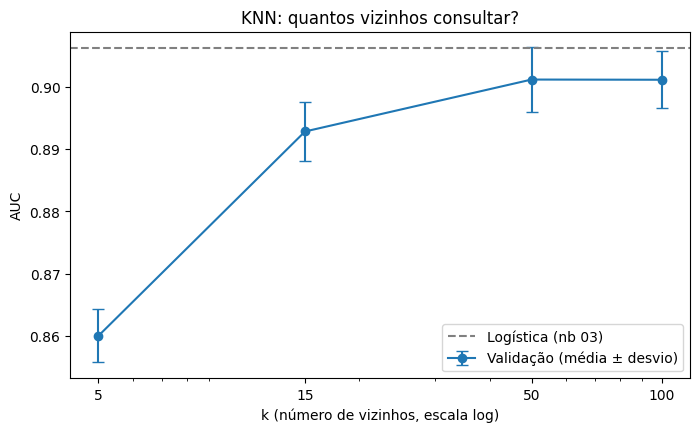

Maior AUC: k = 50


,AUC validação,± desvio,tempo (s)
5,0.8600,0.0043,24.0471
15,0.8929,0.0048,25.7934
50,0.9012,0.0052,26.7797
100,0.9012,0.0046,25.6277


In [7]:
# ⏱️ Célula lenta (~2 minutos): 4 valores de k × 5 dobras, e cada previsão compara milhares de pessoas.
valores_k = [5, 15, 50, 100]
for k in valores_k:
    avaliar(f"KNN (k={k})", Pipeline([
        ("preparar", preparar_one_hot),
        ("modelo", KNeighborsClassifier(n_neighbors=k)),
    ]), com_treino=False)

# Uma list comprehension monta os nomes; .loc pega essas linhas da tabela de resultados.
curva_knn = pd.DataFrame(resultados).T.loc[[f"KNN (k={k})" for k in valores_k], ["AUC validação", "± desvio", "tempo (s)"]]
curva_knn.index = valores_k

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(valores_k, curva_knn["AUC validação"], yerr=curva_knn["± desvio"], marker="o", capsize=4,
            label="Validação (média ± desvio)")   # errorbar: a linha com barrinhas de desvio padrão
ax.axhline(resultados["Logística (nb 03)"]["AUC validação"], color="gray", linestyle="--", label="Logística (nb 03)")
ax.set_xscale("log")   # escala logarítmica: 5, 50 e 500 ficam igualmente espaçados
ax.set_xticks(valores_k, valores_k)
ax.set_xlabel("k (número de vizinhos, escala log)")
ax.set_ylabel("AUC")
ax.set_title("KNN: quantos vizinhos consultar?")
ax.legend()
plt.show()

melhor_k = curva_knn["AUC validação"].idxmax()   # o k com a maior AUC média
print(f"Maior AUC: k = {melhor_k}")
curva_knn

**Conclusão:** - **k pequeno é ruim:** com **k = 5**, a AUC é só **0,860**. Com poucos vizinhos, a probabilidade só pode valer 0, 0,2, 0,4... e depende demais de quem por acaso está por perto (overfitting).
- A AUC sobe até **k = 50** (**0,9012**) e fica igual em **k = 100** (0,9012). Os dois estão **empatados**, e ficamos com o k = 50.
- Mas mesmo o melhor KNN **não alcança a logística** (0,906, a linha tracejada).
- E ele é **lento**: cerca de 25 segundos para avaliar cada valor de k, contra 2 segundos da logística. Quase todo esse tempo é gasto **prevendo**, como esperado de um aprendiz preguiçoso.

Por que o KNN, que foi bem com as 5 numéricas, perde com todas as colunas? Com o one-hot, cada pessoa passa a ter **72 colunas**, a maioria de zeros e uns, e todas pesam o mesmo na distância. Em muitas dimensões, as distâncias ficam parecidas entre si, e o "vizinho mais próximo" fica menos significativo. Esse problema é conhecido como **maldição da dimensionalidade**. A logística, ao contrário, **aprende** um peso diferente para cada coluna.

## 🎓 Conceito: Naive Bayes

O **Naive Bayes** é baseado no **teorema de Bayes**, que ensina a **atualizar uma probabilidade** quando chega uma informação nova.

Começamos com a **probabilidade a priori**: sem saber nada sobre uma pessoa, a chance de renda alta é 24%. Depois olhamos uma característica, por exemplo, "é casada". O teorema diz como **combinar** as duas coisas:

$$P(\text{renda alta} \mid \text{casado}) = \frac{P(\text{casado} \mid \text{renda alta}) \cdot P(\text{renda alta})}{P(\text{casado})}$$

Lê-se: a chance de renda alta **sabendo que** a pessoa é casada depende de quão comum é estar casado **entre as pessoas de renda alta**, comparado com a população inteira. Todos esses números saem de simples **contagens** no treino.

Com várias colunas, o Naive Bayes faz uma suposição "ingênua" (*naive*): que as colunas são **independentes entre si** dentro de cada classe. Assim, ele pode simplesmente **multiplicar** as "pistas" de cada coluna. Essa suposição quase nunca é verdade (escolaridade e profissão andam juntas, por exemplo), mas o modelo costuma funcionar bem para **ordenar**, e é rapidíssimo.

Analogia: um médico que sabe a frequência de cada sintoma **em quem tem** uma doença e **em quem não tem**. Ao ver febre **e** tosse **e** dor de cabeça, ele multiplica as pistas como se cada sintoma fosse uma evidência independente, mesmo que febre e dor de cabeça costumem vir juntas.

## 4. Uma conta de Bayes "à mão"

Antes do modelo, vamos fazer a conta do teorema com os dados de treino, para ver que ela é só contagem.

In [8]:
renda_alta = y_train == 1
casado = X_train["marital-status"] == "Married-civ-spouse"

p_renda_alta = renda_alta.mean()                       # P(renda alta): a "a priori"
p_casado = casado.mean()                               # P(casado)
p_casado_dado_renda_alta = casado[renda_alta].mean()   # P(casado | renda alta): entre os de renda alta, quantos são casados

p_bayes = p_casado_dado_renda_alta * p_renda_alta / p_casado
print(f"P(renda alta)           = {p_renda_alta:.3f}")
print(f"P(casado)               = {p_casado:.3f}")
print(f"P(casado | renda alta)  = {p_casado_dado_renda_alta:.3f}")
print(f"\nPelo teorema de Bayes:  P(renda alta | casado) = {p_bayes:.3f}")
print(f"Contando diretamente:   P(renda alta | casado) = {renda_alta[casado].mean():.3f}")

P(renda alta)           = 0.239
P(casado)               = 0.457
P(casado | renda alta)  = 0.856

Pelo teorema de Bayes:  P(renda alta | casado) = 0.448
Contando diretamente:   P(renda alta | casado) = 0.448


**Conclusão:** o teorema de Bayes, calculado só com três contagens, dá **exatamente** o mesmo resultado que contar diretamente: **44,8%** dos casados têm renda alta. Veja como a informação "casado" **atualiza** a probabilidade:
- Antes (a priori): **23,9%**.
- Entre as pessoas de renda alta, **85,6%** são casadas, contra **45,7%** na população inteira. Ser casado é bem mais comum entre quem ganha mais.
- Depois (sabendo que é casado): **44,8%**, quase o dobro.

O Naive Bayes faz essa mesma atualização **coluna por coluna**, multiplicando as pistas de cada uma.

## 5. Naive Bayes com todas as colunas

O `CategoricalNB` do scikit-learn trabalha com **categorias**. Montamos o pipeline assim:
- **Numéricas → faixas** com o `KBinsDiscretizer(strategy="quantile")`, que divide cada coluna em faixas com aproximadamente o mesmo número de pessoas (por exemplo, idade de 17 a 22, de 22 a 26...).
- **Categóricas → números** com o `OrdinalEncoder`. Aqui a ordem inventada **não importa**: o Naive Bayes só **conta** quantas vezes cada categoria aparece em cada classe, sem fazer contas com os números. Passamos a lista completa de categorias de cada coluna (que o pandas já conhece), para que nenhuma categoria seja "nova" numa dobra de validação.

Vamos testar 10 e 20 faixas.

In [9]:
# A lista de categorias possíveis de cada coluna, mais o "Desconhecido" dos valores ausentes.
categorias = [list(X[coluna].cat.categories) + ["Desconhecido"] for coluna in colunas_categoricas]


def naive_bayes_com(n_faixas):
    """Monta o pipeline do Naive Bayes com um número de faixas para as colunas numéricas."""
    return Pipeline([
        ("preparar", ColumnTransformer([
            # encode="ordinal": cada faixa vira um número (0, 1, 2...); subsample=None: usa todas as linhas.
            ("faixas", KBinsDiscretizer(n_bins=n_faixas, encode="ordinal", strategy="quantile", subsample=None),
             colunas_numericas),
            ("categoricas", Pipeline([
                ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
                ("numerar", OrdinalEncoder(categories=categorias)),
            ]), colunas_categoricas),
        ])),
        ("modelo", CategoricalNB()),
    ])


for n_faixas in [10, 20]:
    avaliar(f"Naive Bayes ({n_faixas} faixas)", naive_bayes_com(n_faixas))
pd.DataFrame(resultados).T.loc[["Logística (nb 03)", "Naive Bayes (10 faixas)", "Naive Bayes (20 faixas)"]]

/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:397: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:397: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are remo

/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/home/joaol/Projects/Machine Learning/ML-02-Intr

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1219
Naive Bayes (10 faixas),0.8782,0.0040,0.8792,0.7992,0.4757
Naive Bayes (20 faixas),0.8950,0.0033,0.8960,0.8140,0.4766


Com 20 faixas o resultado melhorou bastante. Por quê? Vamos ver em quantas faixas cada coluna numérica foi **realmente** dividida.

In [10]:
for n_faixas in [10, 20]:
    discretizador = KBinsDiscretizer(n_bins=n_faixas, encode="ordinal", strategy="quantile", subsample=None)
    discretizador.fit(X_train[colunas_numericas])
    # bin_edges_ guarda os limites das faixas de cada coluna; o número de faixas é o número de limites - 1.
    faixas_reais = {coluna: len(limites) - 1 for coluna, limites in zip(colunas_numericas, discretizador.bin_edges_)}
    print(f"Pedindo {n_faixas} faixas, cada coluna ficou com: {faixas_reais}")

Pedindo 10 faixas, cada coluna ficou com: {'age': 10, 'education-num': 6, 'capital-gain': 1, 'capital-loss': 1, 'hours-per-week': 6}
Pedindo 20 faixas, cada coluna ficou com: {'age': 20, 'education-num': 9, 'capital-gain': 2, 'capital-loss': 1, 'hours-per-week': 11}


/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:397: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/home/joaol/Projects/Machine Learning/ML-02-Introducao-classificacao/.venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:397: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are remo

**Conclusão:** a conta mostra um detalhe que derrubava o modelo com 10 faixas:
- **`capital-gain` ficou com só 1 faixa** quando pedimos 10. Como 92% das pessoas têm ganho zero, todos os limites das faixas de quantis caem em zero, e o discretizador junta tudo numa faixa só. A coluna mais reveladora sobre a renda simplesmente **desapareceu** do modelo!
- Com 20 faixas, o último limite de quantil já passa de zero, e o ganho de capital ganha **2 faixas**: "até ~4,9 mil" e "acima de ~4,9 mil". Só isso levou a AUC de **0,878** para **0,895**.
- `capital-loss` ficou com **1 faixa** nos dois casos: ele continua fora do modelo.

**Lição:** confira o que o pré-processamento **realmente** fez com cada coluna. Uma etapa que parece inofensiva ("dividir em 10 faixas") pode apagar a informação mais importante sem dar nenhum aviso.

Mesmo com 20 faixas, o Naive Bayes (**0,895**) fica abaixo da logística (0,906). A suposição de independência cobra o seu preço: estado civil e papel na família (`relationship`), por exemplo, contam quase a mesma história, e o Naive Bayes **conta essa pista duas vezes**. Em compensação, ele é o mais rápido de todos (menos de meio segundo para as 5 dobras).

## 🎓 Conceito: SVM (máquina de vetores de suporte)

O **SVM** procura a fronteira que separa as classes com a **maior margem** possível: a "rua" mais larga que cabe entre as duas classes. Só os pontos na beira da rua (os **vetores de suporte**) definem onde ela passa; os pontos longe da fronteira não fazem diferença.

Analogia: separar dois times num pátio com uma faixa pintada no chão. Entre todas as faixas possíveis, o SVM escolhe a que fica **o mais longe possível** dos jogadores mais próximos de cada lado, para que um pequeno passo não troque ninguém de lado.

E se as classes não podem ser separadas por uma reta, como nas meias-luas? O SVM usa o **truque do kernel**: ele calcula as distâncias como se os pontos estivessem num espaço com **mais dimensões**, onde uma separação "reta" existe. Vista de volta no espaço original, essa separação é uma curva. O kernel mais comum é o **RBF**, que gerou a fronteira suave da seção 1.

Duas características práticas:
- O SVM **não produz probabilidades** naturalmente: ele dá uma **pontuação** (o quanto o ponto está longe da fronteira, e de que lado). Para a AUC, isso basta, porque a AUC só precisa da **ordem**. (Com `probability=True`, como na seção 1, ele estima probabilidades com uma validação cruzada interna, mais lenta.)
- O treino do SVM com kernel fica **muito lento** conforme os dados crescem. Vamos medir.

## 6. SVM: o custo de crescer

In [11]:
svm = Pipeline([("preparar", preparar_one_hot), ("modelo", SVC(kernel="rbf"))])

# Medimos o tempo de treino com amostras de tamanhos diferentes do treino.
tempos = {}
for n in [2000, 4000, 8000, 16000]:
    amostra = X_train[colunas].sample(n, random_state=42)   # .sample sorteia n linhas
    inicio = time.time()
    svm.fit(amostra, y_train.loc[amostra.index])            # .loc[amostra.index]: o y das mesmas linhas
    tempos[n] = time.time() - inicio

tempos = pd.Series(tempos)
# .shift(1) desloca a série uma posição: dividir por ela mostra quantas vezes o tempo cresceu a cada passo.
pd.DataFrame({"segundos para treinar": tempos, "crescimento em relação à linha anterior": tempos / tempos.shift(1)})

,segundos para treinar,crescimento em relação à linha anterior
2000,0.1367,NaN
4000,0.4442,3.2487
8000,1.6221,3.6515
16000,6.3553,3.9179


**Conclusão:** cada vez que o número de pessoas **dobra**, o tempo de treino **quase quadruplica** (×3,2, ×3,7, ×3,9). Isso acontece porque o SVM com kernel compara os exemplos **dois a dois**: com o dobro de pessoas, há o quádruplo de pares. Seguindo esse ritmo, treinar com as ~31 mil pessoas de cada dobra levaria perto de meio minuto, e qualquer ajuste de hiperparâmetros multiplicaria esse tempo. Em datasets com milhões de linhas, o SVM com kernel fica inviável.

In [12]:
# Para comparar de forma justa, avaliamos o SVM e a logística na MESMA amostra de 8.000 pessoas.
amostra = X_train[colunas].sample(8000, random_state=42)
y_amostra = y_train.loc[amostra.index]
avaliar("SVM RBF (amostra de 8 mil)", svm, amostra, y_amostra)
avaliar("Logística (amostra de 8 mil)", logistica, amostra, y_amostra)
pd.DataFrame(resultados).T.loc[["SVM RBF (amostra de 8 mil)", "Logística (amostra de 8 mil)"]]

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
SVM RBF (amostra de 8 mil),0.8990,0.0033,0.9242,0.8561,3.9185
Logística (amostra de 8 mil),0.9053,0.0020,0.9092,0.8528,0.1977


**Conclusão:** na **mesma** amostra de 8 mil pessoas, o SVM (**0,899**) ficou **abaixo** da logística (**0,905**) e foi 20 vezes mais lento. A AUC no treino (0,924 contra 0,909) mostra que ele se ajusta mais aos dados, mas isso não se converteu em acertos em pessoas novas.

Ser honesto aqui é importante: o SVM tem hiperparâmetros (`C` e `gamma`) que poderiam ser ajustados, e talvez melhorassem o resultado. Mas, com o custo de treino crescendo tão rápido, cada tentativa sai cara. Para dados **tabulares** com dezenas de milhares de linhas, como o Adult, o SVM raramente é a primeira escolha. Ele brilha em datasets **menores**, com fronteiras curvas, e foi muito usado em problemas como reconhecimento de imagens antes da era das redes neurais.

## 7. Gradient boosting para classificação

No ML-01 (notebook 08), o **gradient boosting** foi o melhor modelo: árvores treinadas **em sequência**, cada uma corrigindo os erros das anteriores. Na classificação, a ideia é a mesma, só que as árvores corrigem a **pontuação** $z$ (a mesma da regressão logística), que depois passa pela sigmoide para virar probabilidade.

O `HistGradientBoostingClassifier` tem duas vantagens enormes para o Adult:
- **Entende colunas categóricas sozinho:** com `categorical_features="from_dtype"`, ele reconhece as colunas do tipo `category` do pandas e faz cortes do tipo "profissão está no grupo {A, C, F}?", sem one-hot.
- **Aceita valores ausentes:** em cada corte, ele aprende para qual lado mandar os `NaN`.

Ou seja: **nenhum pré-processamento**. Passamos a tabela original e pronto.

In [13]:
boosting = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42)
avaliar("Gradient boosting", boosting).loc[["Logística (nb 03)", "Gradient boosting"]]

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1219
Gradient boosting,0.9285,0.0029,0.9454,0.8718,2.1267


**Conclusão:** com as configurações padrão, sem nenhum pré-processamento, o gradient boosting chega a **AUC 0,9285**, bem acima da logística (**0,9064**). A acurácia também é a maior até agora: **87,18%**. E ele levou o mesmo tempo da logística (~2 segundos para as 5 dobras).

A AUC no treino (0,945) é um pouco maior que a da validação: há algum overfitting, mas pequeno, ao contrário do que vimos nas meias-luas, onde o dataset tinha só 400 pontos.

## 8. Comparando todos os modelos

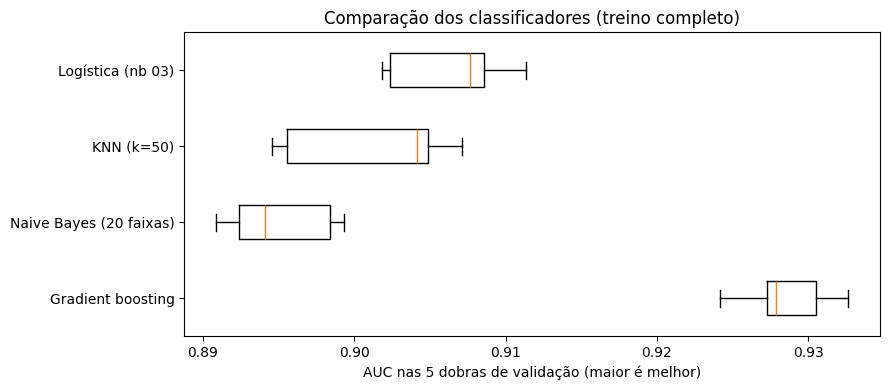

Boosting − logística, dobra a dobra: [0.0219 0.0213 0.0202 0.0254 0.0219]
O boosting venceu em 5 de 5 dobras


,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1219
KNN (k=50),0.9012,0.0052,NaN,0.8475,26.7797
Naive Bayes (20 faixas),0.8950,0.0033,0.8960,0.8140,0.4766
Gradient boosting,0.9285,0.0029,0.9454,0.8718,2.1267


In [14]:
# O SVM fica de fora: foi avaliado numa amostra menor, e a comparação não seria justa.
nomes_finais = ["Logística (nb 03)", f"KNN (k={melhor_k})", "Naive Bayes (20 faixas)", "Gradient boosting"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([auc_por_dobra[n] for n in nomes_finais], vert=False)
ax.set_yticks(range(1, len(nomes_finais) + 1), nomes_finais)
ax.set_xlabel("AUC nas 5 dobras de validação (maior é melhor)")
ax.set_title("Comparação dos classificadores (treino completo)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Comparação pareada (ML-01, notebook 05): o boosting vence a logística em quantas dobras?
diferencas = auc_por_dobra["Gradient boosting"] - auc_por_dobra["Logística (nb 03)"]
print("Boosting − logística, dobra a dobra:", diferencas.round(4))
print(f"O boosting venceu em {(diferencas > 0).sum()} de 5 dobras")

pd.DataFrame(resultados).T.loc[nomes_finais]

**Conclusão:** - **O gradient boosting vence todos com folga.** Mesmo a pior dobra dele (~0,924) é melhor que a melhor dobra de qualquer outro modelo (~0,911, da logística).
- **A comparação pareada confirma:** o boosting venceu a logística nas **5 dobras**, sempre por **0,020 a 0,025** de AUC. Não é sorte da divisão.
- **Logística, KNN e Naive Bayes ficam próximos** (0,906, 0,901 e 0,895). As caixas da logística e do KNN se sobrepõem.
- O SVM ficou de fora do gráfico, mas na amostra de 8 mil pessoas também perdeu para a logística (0,899 × 0,905).

Não existe um "melhor classificador" universal. Aqui, num problema **tabular** com colunas de tipos misturados, o boosting ganha. No notebook extra 08, com **imagens**, a história vai ser outra.

## 9. Por que o boosting vence? As curvas aprendidas

Para fechar, vamos conferir se o boosting aprendeu os padrões não lineares do começo do notebook. Usamos a **dependência parcial** (ML-01, notebook 07): ela mostra como a probabilidade média prevista muda quando variamos **uma** coluna, mantendo as outras como estão.

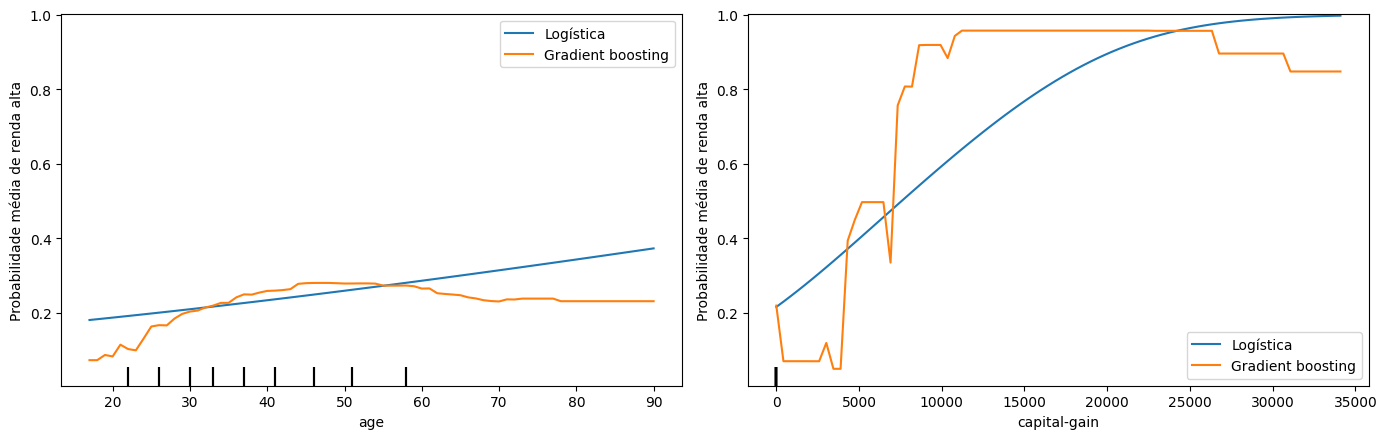

In [15]:
logistica.fit(X_train[colunas], y_train)
boosting.fit(X_train[colunas], y_train)

# O PartialDependenceDisplay pede colunas decimais (float), e não inteiras.
# .astype({coluna: tipo}) converte só as colunas indicadas.
X_curvas = X_train[colunas].astype({"age": float, "capital-gain": float})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for modelo, nome, cor in [(logistica, "Logística", "tab:blue"), (boosting, "Gradient boosting", "tab:orange")]:
    PartialDependenceDisplay.from_estimator(
        modelo, X_curvas, ["age", "capital-gain"],
        response_method="predict_proba",   # a curva mostra a probabilidade de renda alta
        method="brute",                     # cálculo "na força bruta", necessário para usar predict_proba
        grid_resolution=80,                 # quantos valores testar em cada coluna
        percentiles=(0, 0.995),             # ignora os 0,5% de valores mais extremos
        ax=axes, line_kw={"label": nome, "color": cor},
    )
for ax in axes:
    ax.set_ylabel("Probabilidade média de renda alta")
    ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:** a dependência parcial mostra exatamente as limitações que motivaram este notebook:
- **Idade (esquerda):** a logística só sabe desenhar uma curva que sobe sempre, de 0,18 aos 17 anos até 0,37 aos 90. O boosting aprendeu o **"U" invertido**: a probabilidade sobe até ~0,28 por volta dos 45–55 anos e **cai** depois dos 60, para ~0,23.
- **Ganho de capital (direita):** a logística desenha um "S" suave. O boosting aprendeu o **degrau**: com ganho entre ~1 e 4 mil, a probabilidade **cai** para ~0,07 (abaixo de quem tem ganho zero, ~0,22), e acima de ~7 mil ela **salta** para ~0,9.

O boosting não "sabe" nada sobre idade ou investimentos: ele tem liberdade para desenhar curvas de **qualquer formato**, e os dados mostraram qual era o formato certo. É a mesma liberdade que vimos nas fronteiras de decisão da seção 1.

⚠️ O outro lado dessa liberdade aparece nos "dentes" da curva do ganho de capital (como a queda perto de 7 mil e acima de 26 mil), que provavelmente são **ruído** de regiões com poucas pessoas.

## 10. Resumo e próximos passos

**Resultados (validação cruzada no treino)**

| Modelo | Ideia principal | AUC | Acurácia |
|---|---|---|---|
| Naive Bayes (20 faixas) | Teorema de Bayes, colunas independentes | 0,895 | 81,40% |
| KNN (k = 50) | Os vizinhos mais parecidos votam | 0,901 | 84,75% |
| Logística (nb 03) | Soma ponderada das colunas + sigmoide | 0,906 | 85,15% |
| SVM RBF (amostra de 8 mil) | Maior margem + truque do kernel | 0,899* | 85,61%* |
| **Gradient boosting** | Árvores em sequência, corrigindo erros | **0,929 ± 0,003** | **87,18%** |

\* Avaliado numa amostra de 8 mil pessoas; na mesma amostra, a logística teve AUC 0,905.

**Conceitos que você aprendeu**
- **Fronteira de decisão:** cada família de modelos divide o espaço de um jeito (reta, retângulos, curvas).
- **KNN:** distância, vizinhos, o hiperparâmetro k e o **aprendiz preguiçoso**.
- No KNN, **a escala é o peso** de cada coluna, e padronizar é uma escolha a ser testada.
- **Maldição da dimensionalidade:** com muitas colunas, "vizinho mais próximo" perde o sentido.
- **Teorema de Bayes** (probabilidade a priori, atualização com uma pista) e a suposição "ingênua" do **Naive Bayes**.
- **Discretização** (`KBinsDiscretizer`) e o cuidado de conferir o que o pré-processamento fez.
- **SVM:** margem, vetores de suporte, truque do kernel e o custo que cresce com o quadrado dos dados.
- **Gradient boosting** para classificação, com categorias e ausentes nativos.

**Python novo:** `make_moons`, `np.meshgrid`, `np.column_stack`, `.reshape`, `contourf`/`contour`, `axes.ravel()`, `.score`, argumentos com valor padrão `None` e o teste `is None`, a expressão condicional `A if condição else B`, `errorbar`, `.sample`, `.shift`, `bin_edges_` e `.astype({coluna: tipo})`.

**O que ainda falta investigar**
- ⚠️ Os modelos devolvem **probabilidades**, e usamos essas probabilidades para escolher limiares (notebook 04). Mas uma probabilidade de 70% significa mesmo que 70% dessas pessoas têm renda alta? Modelos tão diferentes quanto o Naive Bayes e o KNN calculam as probabilidades de jeitos muito diferentes.
- ⚠️ As classes são **desbalanceadas** (24% × 76%). Uma recomendação comum é "equilibrar as classes" com **pesos**. Será que isso ajuda?

**Próximo notebook (06):** probabilidades e classes desbalanceadas. Vamos conhecer a **calibração** (as probabilidades do modelo merecem confiança?), a **perda logarítmica** e testar, com honestidade, o **`class_weight="balanced"`**.